# Case Study 16 — Payment Processing Outliers: Error, Fraud, VIP or Rare Event?

**Outlier detection (z-score, IQR, log-scale IQR, MAD / robust z) · masking and swamping · segment-aware and
customer-relative detection · domain rules and context flags · the four kinds of outlier · what each treatment does to
the mean, the median and correlations · robust estimators (median, trimmed mean, Huber) · a defensible outlier policy**

| | |
|---|---|
| **Domain** | Payments processing: transaction monitoring |
| **Stakeholders** | Head of Payments Operations, Risk Analytics |
| **Difficulty** | Intermediate |
| **Importance** | 🟠 SHOULD GO THROUGH |
| **Builds on** | Case 01 (descriptives), Case 05 (outliers and correlation), Case 10 (influential points) |
| **Data** | 20,230 payments over one quarter |

> **This dataset is synthetic** and was generated to reproduce a realistic business scenario. It is not actual
> customer data. See `src/generate_data.py`. A separate **answer key** (the true type of each payment) exists only
> because the data are simulated; the notebook opens it **only in Section 13**, to grade the methods. In real life
> nobody knows the truth, which is exactly why the reasoning in Sections 5–12 matters.

**What you will learn**

1. Why "more than 3 standard deviations from the mean" is a poor outlier rule for money data, and what to use instead.
2. That **unusual is not the same as wrong**: an outlier can be a **data error**, **fraud**, a legitimate **VIP**
   transaction, or a rare but real **event**, and each needs a different action.
3. How to combine **statistics** (how unusual?) with **context** (why?) to classify outliers.
4. What each treatment (delete, correct, cap, ignore) does to averages and correlations.

## Section 1 — Business context

You are a data scientist in **Risk Analytics** at a payments processor. The monitoring dashboard flags every payment
**more than 3 standard deviations above the mean amount**. Operations reviews the flags by hand. The Head of Payments
Operations writes:

> *"Every quarter the dashboard flags a few dozen transactions. Most turn out to be harmless: a jeweller's big sale,
> a wholesale order. Meanwhile we keep finding fraud and keying mistakes that the dashboard never flagged. My team
> has stopped trusting it. Finance also uses average ticket size in its forecasts, and it moves a lot from quarter to
> quarter. Should we delete the outliers? Which ones? And how do we flag the right ones next time?"*

## Section 2 — Business questions

1. How many unusual payments are there, and does the answer depend on the method?
2. Why does the dashboard flag the wrong payments and miss the right ones?
3. For unusual payments, what are they: **errors, fraud, VIP or rare events**?
4. Which ones should be deleted, corrected, investigated or left alone?
5. How does the treatment of outliers change the average ticket size and other statistics Finance uses?

## Section 3 — Statistical translation

| # | Business question | Statistical question | Method |
|---|---|---|---|
| 1 | How many? | How many points fall outside a "normal range", defined in different ways? | z-score, IQR, log-IQR, MAD |
| 2 | Why the wrong ones? | Does one outlier hide others (masking)? Is "normal" the same for every segment and customer? | Iterated z-scores, segment-level and customer-relative detection |
| 3 | What are they? | What do unusual points look like on **other** variables? | Profiling, rule-based triage |
| 4 | Treatment | Which treatment gives estimates closest to the truth? | Compare mean, median, trimmed mean, Huber, winsorising, correction |
| 5 | Finance | How sensitive are the mean ticket and correlations to a few points? | Bootstrap, correlation with/without |

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "00_shared_resources").is_dir())
sys.path.insert(0, str(ROOT / "00_shared_resources"))
from utils import case_paths, save_table, fmt_money, fmt_p, rng_for_case
from plotting import set_style, save_fig, add_note, thousands_formatter, COLORS, CATEGORICAL, PRIMARY, HIGHLIGHT, INK, INK_MUTED

CASE_DIR = ROOT / "case_studies" / "16_payment_outliers"
PATHS = case_paths(CASE_DIR)
set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
rng = rng_for_case(1616)
kfmt = thousands_formatter("₹", "k", 1e3, 0)
TYPE_COL = {"normal": "#bdbdbd", "entry_error": COLORS["orange"], "fraud": COLORS["red"], "vip": COLORS["blue"], "festival": COLORS["violet"]}

def robust_z(x):
    # 0.6745 (x − median) / MAD ≈ an ordinary z-score for normal data, but not distorted by outliers.
    x = np.asarray(x, dtype=float)
    med = np.median(x)
    mad = np.median(np.abs(x - med))
    return 0.6745 * (x - med) / mad

## Section 4 — Load the data and check basic validity

In [2]:
pay = pd.read_csv(PATHS["data"] / "payments.csv")
print(f"{pay.shape[0]:,} payments × {pay.shape[1]} columns;  duplicate ids: {pay['txn_id'].duplicated().sum()};  missing: {pay.isna().sum().sum()}")
print(f"Business-rule checks: amounts ≤ 0: {(pay['amount'] <= 0).sum()};  hours outside 0–23: {((pay['hour'] < 0) | (pay['hour'] > 23)).sum()};  "
      f"customer averages ≤ 0: {(pay['customer_avg_amount_90d'] <= 0).sum()}")
display(pay.head())

pay["log_amount"] = np.log(pay["amount"])
pay["ratio"] = pay["amount"] / pay["customer_avg_amount_90d"]          # amount relative to this customer's usual payment
pay["log_ratio"] = np.log(pay["ratio"])
pay["night"] = ((pay["hour"] < 6) | (pay["hour"] >= 22)).astype(int)
pay["burst"] = (pay["txns_last_24h"] >= 4).astype(int)
pay["risk_flags"] = pay["new_device"] + pay["geo_mismatch"] + pay["night"] + pay["burst"]
pay["segment"] = pd.Categorical(pay["merchant_segment"], categories=["Grocery", "Restaurant", "Fuel", "Utilities", "Electronics", "B2B wholesale", "Jewellery"])

20,230 payments × 13 columns;  duplicate ids: 0;  missing: 0
Business-rule checks: amounts ≤ 0: 0;  hours outside 0–23: 0;  customer averages ≤ 0: 0


,txn_id,merchant_segment,payment_method,entry_channel,hour,is_festival_week,customer_tier,customer_tenure_months,customer_avg_amount_90d,new_device,geo_mismatch,txns_last_24h,amount
0,PY161000000,Grocery,UPI,Online,20,1,Affluent,203,513.0000,0,0,4,532.0000
1,PY161000001,B2B wholesale,UPI,Online,13,0,Standard,85,"38,688.0000",0,0,2,"59,165.0000"
2,PY161000002,Electronics,UPI,Online,21,0,Standard,16,"39,497.0000",0,0,1,"54,934.0000"
3,PY161000003,Restaurant,UPI,Online,21,0,Standard,54,"1,449.0000",0,0,3,"2,533.0000"
4,PY161000004,Electronics,UPI,Online,16,0,Standard,11,"4,399.0000",0,0,2,"5,147.0000"


The data is complete, and every value is logically possible (positive amounts, valid hours). Passing these
**validity checks** does not mean there are no problems: a decimal-slip error is still a positive number.

Besides the amount, each payment has **context** known at the time: the customer's usual (90-day average) payment,
tenure and tier, whether the device is new, whether the location mismatches, how many payments the customer made in
the last 24 hours, the hour, the entry channel and whether it is festival week. We build four **risk flags** from
this context: new device, location mismatch, night time (10 pm to 6 am), and a burst of 4+ payments in 24 hours.

## Section 5 — Descriptive statistics

In [3]:
seg = pay.groupby("segment", observed=True)["amount"].agg(n="size", median="median", mean="mean", p99=lambda s: s.quantile(0.99),
                                                         maximum="max", skewness=lambda s: stats.skew(s))
seg["mean ÷ median"] = seg["mean"] / seg["median"]
save_table(seg, "amount_by_segment", PATHS["tables"])
display(seg)
a = pay["amount"]
print(f"Overall: mean {fmt_money(a.mean())}, median {fmt_money(a.median())}, SD {fmt_money(a.std())}, skewness {stats.skew(a):.0f}, "
      f"max {fmt_money(a.max())} ({a.max() / a.median():,.0f}× the median)")

,n,median,mean,p99,maximum,skewness,mean ÷ median
segment,,,,,,,
Grocery,4838,533.5000,862.9857,"3,896.3000","144,000.0000",31.4208,1.6176
Restaurant,3226,"1,046.5000","1,626.1457","7,103.0000","307,100.0000",40.1901,1.5539
Fuel,3088,"1,722.5000","2,636.1995","12,423.4900","161,900.0000",18.0235,1.5304
Utilities,1965,"2,168.0000","3,502.8616","15,390.8800","1,006,500.0000",42.8768,1.6157
Electronics,2470,"10,741.5000","17,563.3794","90,261.1400","2,326,700.0000",30.1371,1.6351
B2B wholesale,3801,"28,698.0000","49,639.3612","244,366.0000","5,488,600.0000",23.2172,1.7297
Jewellery,842,"47,573.0000","80,009.3634","398,309.8200","4,229,200.0000",17.3274,1.6818


Overall: mean ₹16,010, median ₹2,148, SD ₹89,546, skewness 40, max ₹5,488,600 (2,555× the median)


**Observation.** Payment amounts span three orders of magnitude between segments (a typical grocery payment is a few
hundred rupees; a jewellery payment tens of thousands), and the distribution is extremely **right-skewed**: the mean is
several times the median and the maximum is thousands of times the median.

**Interpretation.** "Normal" is not one number. A ₹40,000 payment is routine at a jeweller and extraordinary at a
grocer. Any rule that uses one mean and one standard deviation for all payments will flag whole segments and miss
unusual payments in cheap ones.

## Section 6 — Visualisation

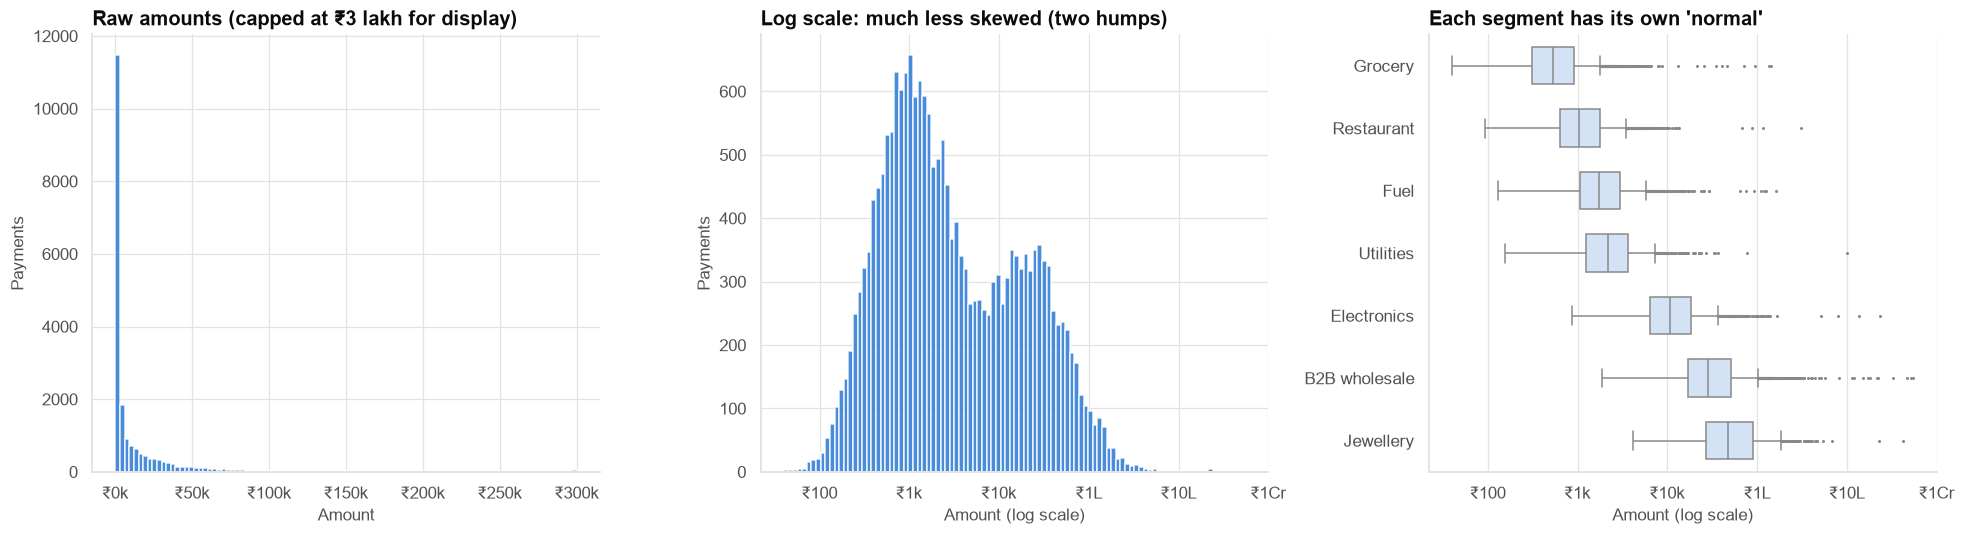

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ax = axes[0]
ax.hist(pay["amount"].clip(upper=300_000), bins=100, color=PRIMARY, alpha=0.85)
ax.xaxis.set_major_formatter(kfmt)
ax.set(title="Raw amounts (capped at ₹3 lakh for display)", xlabel="Amount", ylabel="Payments")
ax = axes[1]
ax.hist(pay["log_amount"], bins=100, color=PRIMARY, alpha=0.85)
ticks = np.log([100, 1_000, 10_000, 1e5, 1e6, 1e7])
ax.set_xticks(ticks, ["₹100", "₹1k", "₹10k", "₹1L", "₹10L", "₹1Cr"])
ax.set(title="Log scale: much less skewed (two humps)", xlabel="Amount (log scale)", ylabel="Payments")
ax = axes[2]
sns.boxplot(data=pay, y="segment", x="amount", ax=ax, color="#cde2fb", fliersize=1, width=0.6)
ax.set_xscale("log")
ax.set_xticks([100, 1_000, 10_000, 1e5, 1e6, 1e7], ["₹100", "₹1k", "₹10k", "₹1L", "₹10L", "₹1Cr"])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set(title="Each segment has its own 'normal'", xlabel="Amount (log scale)", ylabel="")
fig.tight_layout()
save_fig(fig, "fig01_amount_distribution", PATHS["figures"])
plt.show()

**Observation.** On the raw scale, nearly everything is crushed against zero, and a handful of points stretch the axis
out to crores. On the log scale, the distribution is far less skewed: two humps (the cheap segments and the expensive
ones), with a few points far to the right. The
segment boxplots show a different level and spread for each segment, with outlying points in several of them.

**Interpretation.** The natural scale for payments is **multiplicative**: ×2 means the same in every segment. The
log scale respects that. This choice matters for every method below.

## Section 7 — Method selection: the detectors

| Detector | Rule | Assumes | Weakness |
|---|---|---|---|
| **z-score** (the dashboard) | (x − mean) / SD > 3 | roughly normal data, no extreme outliers | Mean and SD are **themselves distorted by outliers** (masking); skewed data flag many "outliers" |
| **IQR fence** | x > Q3 + 1.5 × IQR | none | On skewed data flags a large fraction of ordinary points (swamping) |
| **IQR fence on log(x)** | same on log scale | log-normal-ish data | One global scale for all segments |
| **MAD / robust z** | 0.6745 (x − median) / MAD > 3.5 | none (uses median and MAD) | Same global-scale issue unless applied within groups |
| **Segment-aware** | robust z **within** each merchant segment | segment-level normality on the log scale | Needs enough data per segment |
| **Customer-relative** | robust z of log(amount ÷ customer's own average) | a reliable customer history | New customers lack a history |
| **Context flags** | several risk signals at once | domain knowledge | Rules need maintenance; not a statistical test |

The **MAD** (median absolute deviation) is the median of |x − median|. Because medians ignore extreme values, a few
huge outliers cannot inflate the "normal" range. The constant 0.6745 makes the robust z comparable to an ordinary
z-score; 3.5 is the usual cut-off (Iglewicz & Hoaglin).

## Section 8 — The standard detectors on the amount

In [5]:
a, la = pay["amount"], pay["log_amount"]
z_raw = (a - a.mean()) / a.std()
q1, q3 = a.quantile([0.25, 0.75]); iqr_raw = a > q3 + 1.5 * (q3 - q1)
l1, l3 = la.quantile([0.25, 0.75]); iqr_log = la > l3 + 1.5 * (l3 - l1)
mad_log = robust_z(la) > 3.5
pay["f_z"] = z_raw > 3
pay["f_iqr_raw"] = iqr_raw
pay["f_iqr_log"] = iqr_log
pay["f_mad_log"] = mad_log
det = pd.DataFrame({"payments flagged": [pay[c].sum() for c in ["f_z", "f_iqr_raw", "f_iqr_log", "f_mad_log"]],
                    "share of all payments": [pay[c].mean() for c in ["f_z", "f_iqr_raw", "f_iqr_log", "f_mad_log"]],
                    "smallest flagged amount (₹)": [pay.loc[pay[c], "amount"].min() for c in ["f_z", "f_iqr_raw", "f_iqr_log", "f_mad_log"]]},
                   index=["z-score > 3 (raw ₹): the dashboard", "IQR fence (raw ₹)", "IQR fence (log ₹)", "MAD robust z > 3.5 (log ₹)"])
save_table(det, "detector_counts", PATHS["tables"])
display(det)

# Masking: remove what the z-rule flags, recompute mean and SD, and look again.
x = a.to_numpy().copy()
rounds = []
for r in range(1, 6):
    m, s = x.mean(), x.std()
    flag = (x - m) / s > 3
    rounds.append({"round": r, "mean (₹)": m, "SD (₹)": s, "threshold = mean + 3 SD (₹)": m + 3 * s, "newly flagged": int(flag.sum()), "remaining": len(x)})
    x = x[~flag]
masking = pd.DataFrame(rounds).set_index("round")
save_table(masking, "masking_rounds", PATHS["tables"])
masking

,payments flagged,share of all payments,smallest flagged amount (₹)
z-score > 3 (raw ₹): the dashboard,58,0.0029,"285,331.0000"
IQR fence (raw ₹),2537,0.1254,"32,016.0000"
IQR fence (log ₹),16,0.0008,"1,006,500.0000"
MAD robust z > 3.5 (log ₹),10,0.0005,"1,792,200.0000"


,mean (₹),SD (₹),threshold = mean + 3 SD (₹),newly flagged,remaining
round,,,,,
1,"16,009.5611","89,543.3076","284,639.4839",58,20230
2,"13,153.4412","27,137.3156","94,565.3880",492,20172
3,"9,905.6983","16,654.5931","59,869.4776",583,19680
4,"7,960.1028","12,462.4660","45,347.5009",554,19097
5,"6,637.0097","9,954.1097","36,499.3387",470,18543


**Observation.**
- The dashboard's z-score rule flags 58 payments, all above ₹2.85 lakh. The **IQR fence on raw ₹** flags **2,537**
  (12.5% of all payments, from ₹32,000 up): on skewed data, ordinary large payments cross the fence. The **log-scale**
  methods flag only 10–16 payments, all of them above ₹10 lakh.
- **Masking:** the standard deviation is ₹89,500, but it falls to about ₹10,000 once the flagged points are removed
  over five rounds. The first-round threshold (mean + 3 SD ≈ ₹2.85 lakh) is set by the extreme points themselves.
- **Swamping:** once the extremes are gone, the same rule flags 492, then 583, 554 and 470 further payments in the
  next rounds: skewed data always have a long tail that looks extreme relative to a normal distribution.

**Interpretation.** A z-score uses the mean and SD, which are the statistics **most damaged by outliers**: the
outliers inflate the threshold that is supposed to catch them (masking). Skewed data cause the opposite problem,
**swamping**: many ordinary points look extreme on the raw scale. Robust methods (medians, MAD) and the right scale
(log) address both.

### Where do the flags fall?

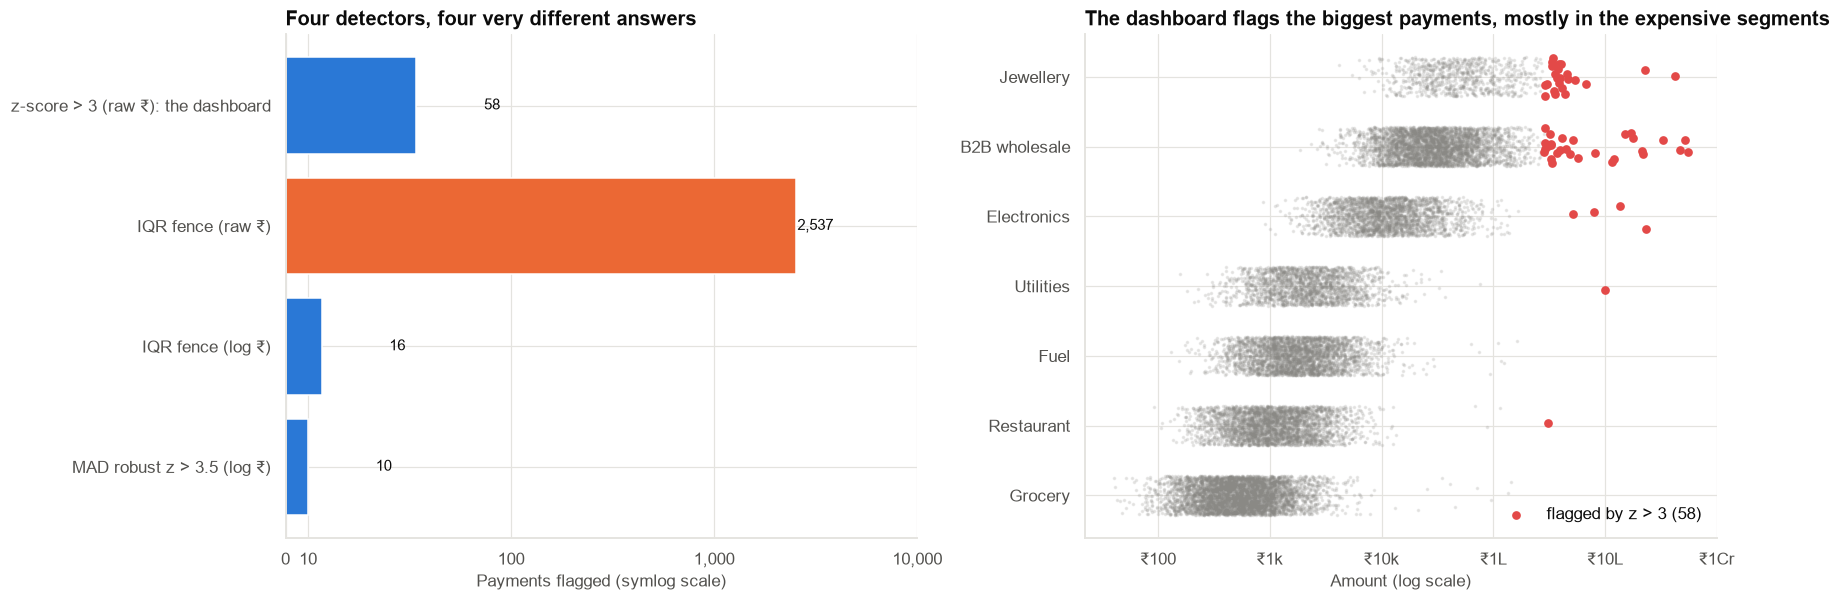

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.6))
ax = axes[0]
order = list(det.index)[::-1]
ax.barh(order, det.loc[order, "payments flagged"], color=[PRIMARY, PRIMARY, HIGHLIGHT, PRIMARY])
for i, v in enumerate(det.loc[order, "payments flagged"]):
    ax.text(v + 30, i, f"{int(v):,}", va="center", fontsize=10)
ax.set_xscale("symlog", linthresh=100)
ax.set_xticks([0, 10, 100, 1_000, 10_000], ["0", "10", "100", "1,000", "10,000"])
ax.set(xlabel="Payments flagged (symlog scale)", title="Four detectors, four very different answers")
ax = axes[1]
jit = rng.uniform(-0.28, 0.28, len(pay))
ci = pay["segment"].cat.codes
ax.scatter(pay["amount"], ci + jit, s=2, alpha=0.15, color=INK_MUTED)
fl = pay["f_z"]
ax.scatter(pay.loc[fl, "amount"], ci[fl] + jit[fl], s=22, color=COLORS["red"], label=f"flagged by z > 3 ({fl.sum()})", zorder=3)
ax.set_xscale("log")
ax.set_xticks([100, 1_000, 10_000, 1e5, 1e6, 1e7], ["₹100", "₹1k", "₹10k", "₹1L", "₹10L", "₹1Cr"])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_yticks(range(len(pay["segment"].cat.categories)), pay["segment"].cat.categories)
ax.set(xlabel="Amount (log scale)", title="The dashboard flags the biggest payments, mostly in the expensive segments")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
save_fig(fig, "fig02_detectors", PATHS["figures"])
plt.show()

**Observation.** The red points (flagged by the dashboard) are the largest payments overall, and almost all of
them are in **B2B wholesale** and **Jewellery** (the two most expensive segments). Grocery and Fuel have **no** flags,
and Restaurant and Utilities one each, because a payment there is small in absolute terms, even when it is hundreds
of times the customer's usual.

## Section 9 — Detection that respects context

### 9.1 Segment-aware and customer-relative detection

,payments flagged,smallest flagged amount (₹),median flagged amount (₹)
unusual for its merchant segment (robust z of log ₹ > 3.5),50,"8,622.0000","140,450.0000"
unusual for this customer (robust z of log amount ÷ customer average > 3.5),58,"2,528.0000","121,950.0000"
"three or more risk flags (new device, location mismatch, night, burst)",73,106.0000,"10,305.0000"


Risk flags among ALL payments (share with k flags): {0: 0.7239, 1: 0.2468, 2: 0.0257, 3: 0.0017, 4: 0.0019}


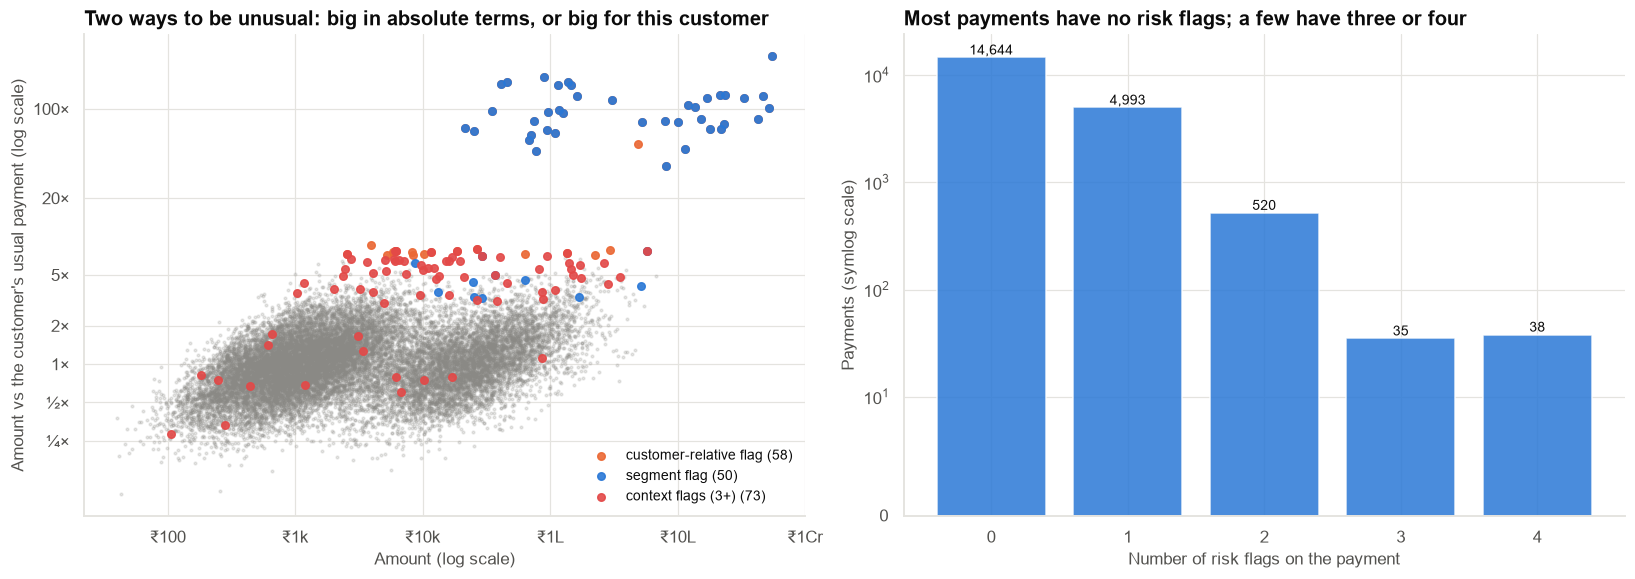

In [7]:
pay["z_segment"] = pay.groupby("segment", observed=True)["log_amount"].transform(robust_z)
pay["z_customer"] = robust_z(pay["log_ratio"])
pay["f_segment"] = pay["z_segment"] > 3.5
pay["f_customer"] = pay["z_customer"] > 3.5
pay["f_context"] = pay["risk_flags"] >= 3
lens = pd.DataFrame({"payments flagged": [pay[c].sum() for c in ["f_segment", "f_customer", "f_context"]]},
                    index=["unusual for its merchant segment (robust z of log ₹ > 3.5)",
                           "unusual for this customer (robust z of log amount ÷ customer average > 3.5)",
                           "three or more risk flags (new device, location mismatch, night, burst)"])
lens["smallest flagged amount (₹)"] = [pay.loc[pay[c], "amount"].min() for c in ["f_segment", "f_customer", "f_context"]]
lens["median flagged amount (₹)"] = [pay.loc[pay[c], "amount"].median() for c in ["f_segment", "f_customer", "f_context"]]
save_table(lens, "context_lens_counts", PATHS["tables"])
display(lens)
print("Risk flags among ALL payments (share with k flags):", pay["risk_flags"].value_counts(normalize=True).sort_index().round(4).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(15, 5.4))
ax = axes[0]
ax.scatter(pay["log_amount"], pay["log_ratio"], s=3, alpha=0.2, color=INK_MUTED)
for col, c, lab in [("f_customer", COLORS["orange"], "customer-relative flag"), ("f_segment", PRIMARY, "segment flag"), ("f_context", COLORS["red"], "context flags (3+)")]:
    ax.scatter(pay.loc[pay[col], "log_amount"], pay.loc[pay[col], "log_ratio"], s=24, color=c, alpha=0.9, label=f"{lab} ({pay[col].sum()})", zorder=3)
ax.set_xticks(np.log([100, 1_000, 10_000, 1e5, 1e6, 1e7]), ["₹100", "₹1k", "₹10k", "₹1L", "₹10L", "₹1Cr"])
ax.set_yticks(np.log([0.25, 0.5, 1, 2, 5, 20, 100]), ["¼×", "½×", "1×", "2×", "5×", "20×", "100×"])
ax.set(xlabel="Amount (log scale)", ylabel="Amount vs the customer's usual payment (log scale)",
       title="Two ways to be unusual: big in absolute terms, or big for this customer")
ax.legend(frameon=False, fontsize=9, loc="lower right")
ax = axes[1]
prof = pay.groupby("risk_flags")["ratio"].agg(["size", "median"])
ax.bar(prof.index.astype(str), prof["size"], color=PRIMARY, alpha=0.85)
for i, (n_, m_) in enumerate(zip(prof["size"], prof["median"])):
    ax.text(i, n_, f"{n_:,}", ha="center", va="bottom", fontsize=9)
ax.set_yscale("symlog", linthresh=10)
ax.set(xlabel="Number of risk flags on the payment", ylabel="Payments (symlog scale)",
       title="Most payments have no risk flags; a few have three or four")
fig.tight_layout()
save_fig(fig, "fig03_context_lenses", PATHS["figures"])
plt.show()

**Observation.**
- The **segment** detector flags 50 payments (smallest ₹8,600, median ₹1.4 lakh): extreme for their own segment.
- The **customer-relative** detector flags 58 payments, including some of only ₹2,500, because they are many times
  that customer's usual amount, which the dashboard never saw.
- Payments with **3+ risk flags** (73) are very rare (0.4% of payments) and their median amount is only ₹10,000: they
  are **not** at the extreme top of the amount distribution.
- The lenses select different payments: unusual in the **population** (large ₹), unusual for the **customer** (big
  ratio), unusual in **context** (several risk signals).

**Interpretation.** "Unusual" has several meanings. Money data need **both** a relative view (compared with this
segment or this customer) and **context** (device, location, time, burst). Each lens finds something the others
miss.

## Section 10 — What do the dashboard's flags look like? Profile the queue

In [8]:
queue = pay[pay["f_z"]].copy()
profile = pd.DataFrame({
    "payments": [len(queue)],
    "median amount (₹)": [queue["amount"].median()],
    "median ratio to customer's usual": [queue["ratio"].median()],
    "manual-keyed share": [(queue["entry_channel"] == "Manual keyed").mean()],
    "new-device share": [queue["new_device"].mean()],
    "location-mismatch share": [queue["geo_mismatch"].mean()],
    "festival-week share": [queue["is_festival_week"].mean()],
    "Privileged tier share": [(queue["customer_tier"] == "Privileged").mean()],
    "median tenure (months)": [queue["customer_tenure_months"].median()],
}, index=["dashboard queue"])
base = pd.DataFrame({
    "payments": [len(pay)], "median amount (₹)": [pay["amount"].median()], "median ratio to customer's usual": [pay["ratio"].median()],
    "manual-keyed share": [(pay["entry_channel"] == "Manual keyed").mean()], "new-device share": [pay["new_device"].mean()],
    "location-mismatch share": [pay["geo_mismatch"].mean()], "festival-week share": [pay["is_festival_week"].mean()],
    "Privileged tier share": [(pay["customer_tier"] == "Privileged").mean()], "median tenure (months)": [pay["customer_tenure_months"].median()]},
    index=["all payments"])
prof2 = pd.concat([profile, base]).T
save_table(prof2, "queue_profile", PATHS["tables"])
display(prof2)

# Three clusters in the queue, visible from the ratio and the channel.
queue["ratio_band"] = pd.cut(queue["ratio"], [0, 2, 10, 1e6], labels=["≈ 1× (in line with the customer)", "2–10× the customer's usual", "> 10× the customer's usual"])
display(queue.groupby("ratio_band", observed=True).agg(n=("amount", "size"), median_amount=("amount", "median"),
                                                       manual_keyed=("entry_channel", lambda s: (s == "Manual keyed").mean()),
                                                       privileged=("customer_tier", lambda s: (s == "Privileged").mean()),
                                                       median_tenure=("customer_tenure_months", "median"),
                                                       festival_week=("is_festival_week", "mean"), risk_flags=("risk_flags", "mean")))

,dashboard queue,all payments
payments,58.0000,"20,230.0000"
median amount (₹),"412,312.5000","2,148.0000"
median ratio to customer's usual,4.2861,1.0029
manual-keyed share,0.3793,0.0178
new-device share,0.0517,0.0412
location-mismatch share,0.0517,0.0180
festival-week share,0.1034,0.0843
Privileged tier share,0.3621,0.0394
median tenure (months),58.5000,41.0000


,n,median_amount,manual_keyed,privileged,median_tenure,festival_week,risk_flags
ratio_band,,,,,,,
≈ 1× (in line with the customer),14,"334,848.5000",0.0000,0.8571,82.0000,0.0000,0.1429
2–10× the customer's usual,23,"375,953.0000",0.0435,0.3478,48.0000,0.2609,0.6087
> 10× the customer's usual,21,"1,704,800.0000",1.0000,0.0476,54.0000,0.0000,0.0000


**Observation.** The dashboard queue (58 payments) is a **mixture**. Splitting it by the ratio to the customer's usual:
- **21 payments over 10× the customer's usual** (median ₹17 lakh): **all manually keyed**, nearly all from
  ordinary-tier customers: a decimal slip?
- **14 payments in line with the customer's own history** (about 1×): 86% from **Privileged, long-tenure** customers,
  none manually keyed: VIPs;
- **23 payments 2–10× the customer's usual**: a mix of festival-week purchases (26%), customers with some risk flags
  and ordinary payments in the tail.

**Interpretation.** The queue is not one kind of thing. A single action ("investigate" or "delete") cannot be right
for all of it. Each cluster has a signature in the **context** variables.

## Section 11 — Domain rules: triage by what the outlier *is*

The **four kinds of outlier** and the evidence that separates them:

| Kind | What happened | Evidence | Treatment |
|---|---|---|---|
| **Data error** | A recording mistake (decimal slip, extra zero, wrong units) | Manually keyed; amount hundreds of × the customer's usual **but plausible after dividing by 100** | **Correct** (if the fix is certain) or remove; fix the process |
| **Fraud** | A genuine transaction by the wrong person | New device, location mismatch, night, burst; amount a few × the customer's usual | **Investigate / block**; never delete (it is the signal) |
| **VIP / legitimate high value** | A real customer with a high level of spending | Long tenure, top tier, amount in line with **their own** history | **Keep**; do not alert; model separately if needed |
| **Rare but real event** | A real, predictable one-off (festival shopping) | Festival week, relevant merchant, regular customer on a known device, modest multiple of usual | **Keep**; add a seasonal feature or an event calendar |

We encode the table as ordered rules (first match wins) and apply it to a payment's context.

In [9]:
def triage(df):
    err = (df["entry_channel"] == "Manual keyed") & (df["ratio"] >= 20) & ((df["ratio"] / 100).between(0.25, 4))
    fraud = (df["risk_flags"] >= 3) & (df["ratio"] >= 2.5)
    vip = (df["customer_tier"] == "Privileged") & (df["customer_tenure_months"] >= 72) & (df["ratio"] < 2) & (df["new_device"] == 0)
    fest = (df["is_festival_week"] == 1) & df["merchant_segment"].isin(["Jewellery", "Electronics"]) & df["ratio"].between(2.5, 6) \
           & (df["new_device"] == 0) & (df["geo_mismatch"] == 0)
    return np.select([err, fraud, vip, fest], ["entry_error", "fraud", "vip", "festival"], default="unexplained")

pay["triage"] = triage(pay)
queue = pay[pay["f_z"]]
tri = queue["triage"].value_counts().rename("dashboard queue").to_frame()
tri["share"] = tri["dashboard queue"] / len(queue)
display(tri)

,dashboard queue,share
triage,,
entry_error,21,0.3621
unexplained,21,0.3621
vip,9,0.1552
festival,5,0.0862
fraud,2,0.0345


**Observation.** Applied to the dashboard's queue of 58, the rules call **21 data errors, 9 VIP, 5 festival and 2 fraud**
payments, leaving **21 "unexplained"** for a human to look at. More than half of the queue (VIP and festival payments
and ordinary large payments) needs no investigation.

## Section 12 — A better screen: three lenses combined

In [10]:
pay["screen"] = pay["f_segment"] | pay["f_customer"] | pay["f_context"]
screen = pay[pay["screen"]]
sc = screen["triage"].value_counts().rename("new screen").to_frame()
sc["share"] = sc["new screen"] / len(screen)
print(f"New screen flags {len(screen)} payments (dashboard: {pay['f_z'].sum()})")
display(sc)

New screen flags 130 payments (dashboard: 58)


,new screen,share
triage,,
fraud,58,0.4462
entry_error,40,0.3077
unexplained,32,0.2462


## Section 13 — Grading the methods (using the answer key)

So far we have used only information available in real life. Because the data are simulated, we can now open the
answer key and check how well each method did. In real life you would instead audit a random sample of flags and a
random sample of unflagged payments to estimate the same numbers.

In [11]:
key = pd.read_csv(PATHS["data"] / "answer_key_teaching_only.csv")
pay = pay.merge(key, on="txn_id")
order_t = ["entry_error", "fraud", "vip", "festival", "normal"]
detectors = {"Dashboard: z > 3 (raw ₹)": "f_z", "IQR fence (raw ₹)": "f_iqr_raw", "IQR fence (log ₹)": "f_iqr_log",
             "MAD robust z (log ₹)": "f_mad_log", "Segment-aware robust z": "f_segment", "Customer-relative robust z": "f_customer",
             "3+ risk flags": "f_context", "New screen (segment OR customer OR context)": "screen"}
true_n = pay["true_type"].value_counts()
grade = pd.DataFrame({name: pay[pay[col]]["true_type"].value_counts().reindex(order_t).fillna(0).astype(int) for name, col in detectors.items()}).T
grade["total flagged"] = grade.sum(axis=1)
grade["share of flags that are errors or fraud"] = (grade["entry_error"] + grade["fraud"]) / grade["total flagged"]
grade["errors caught (of 40)"] = grade["entry_error"] / true_n["entry_error"]
grade["fraud caught (of 60)"] = grade["fraud"] / true_n["fraud"]
save_table(grade, "detector_grading", PATHS["tables"])
display(grade)

true_type,entry_error,fraud,vip,festival,normal,total flagged,share of flags that are errors or fraud,errors caught (of 40),fraud caught (of 60)
Dashboard: z > 3 (raw ₹),21,2,8,5,22,58,0.3966,0.5250,0.0333
IQR fence (raw ₹),38,19,49,67,2364,2537,0.0225,0.9500,0.3167
IQR fence (log ₹),16,0,0,0,0,16,1.0000,0.4000,0.0000
MAD robust z (log ₹),10,0,0,0,0,10,1.0000,0.2500,0.0000
Segment-aware robust z,39,4,0,0,7,50,0.8600,0.9750,0.0667
Customer-relative robust z,40,10,0,0,8,58,0.8621,1.0000,0.1667
3+ risk flags,0,58,0,0,15,73,0.7945,0.0000,0.9667
New screen (segment OR customer OR context),40,60,0,0,30,130,0.7692,1.0000,1.0000


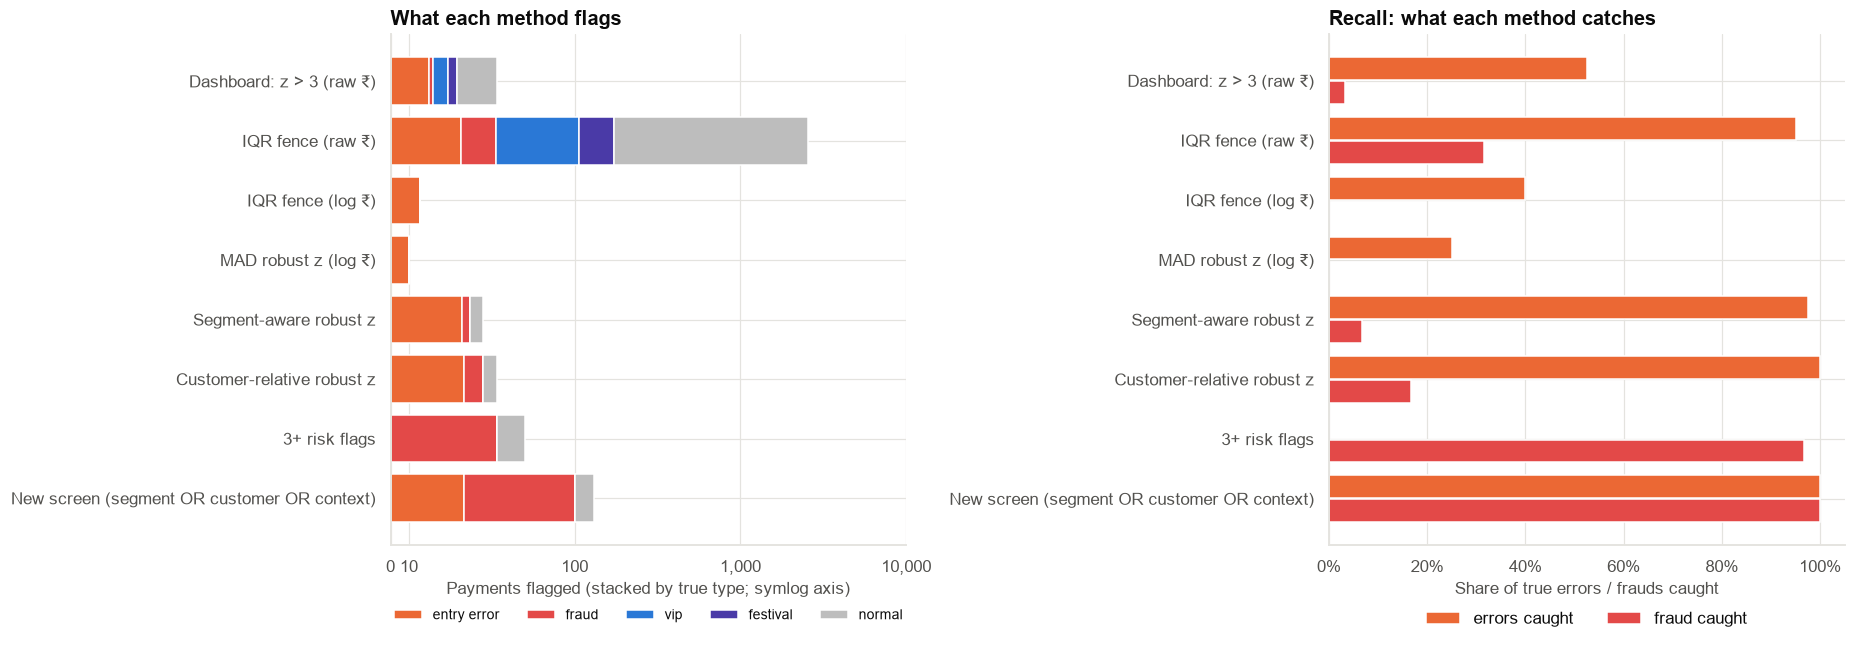

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
ax = axes[0]
show = grade.loc[list(detectors)[::-1], order_t]
left = np.zeros(len(show))
for t in order_t:
    ax.barh(show.index, show[t], left=left, color=TYPE_COL[t], label=t.replace("_", " "))
    left += show[t].to_numpy()
ax.set_xscale("symlog", linthresh=100)
ax.set_xticks([0, 10, 100, 1_000, 10_000], ["0", "10", "100", "1,000", "10,000"])
ax.set(xlabel="Payments flagged (stacked by true type; symlog axis)", title="What each method flags")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=5, fontsize=9)
ax = axes[1]
y_ = np.arange(len(grade))[::-1]
ax.barh(y_ + 0.2, grade["errors caught (of 40)"], height=0.38, color=COLORS["orange"], label="errors caught")
ax.barh(y_ - 0.2, grade["fraud caught (of 60)"], height=0.38, color=COLORS["red"], label="fraud caught")
ax.set_yticks(y_, grade.index)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set(xlabel="Share of true errors / frauds caught", title="Recall: what each method catches")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
fig.tight_layout()
save_fig(fig, "fig04_detector_grading", PATHS["figures"])
plt.show()

**Observation.**
- The **dashboard's z > 3 rule** catches 21 of 40 errors (52%) and **2 of 60 frauds (3%)**; 35 of its 58 flags (60%)
  are harmless (8 VIP, 5 festival, 22 ordinary payments).
- The **IQR fence on raw ₹** catches 95% of errors and 32% of fraud, but among **2,537 flags**: 2.3% are errors or
  fraud.
- The **log-scale detectors** flag 16 and 10 payments, all errors (40% and 25% of the errors), no fraud.
- The **segment-aware** detector catches 39 of 40 errors; the **customer-relative** lens catches all 40 errors and 10
  frauds.
- The **context-flag** lens catches 58 of 60 frauds and no errors.
- The **combined screen** catches **all 40 errors and all 60 frauds** with 130 flags (77% are errors or fraud; the
  other 30 are ordinary payments). It flags no VIP and no festival payment.

**Interpretation.** No single lens works: errors are extreme in ratio, fraud is moderate in ratio but extreme in
context, VIPs and festival buyers are large in ₹ but unremarkable for the customer. A defensible outlier policy
**combines statistics and context**, and keeps the "high but explainable" payments out of the review queue.

### 13.1 How good is the triage?

In [13]:
cand = pay[pay["screen"] | pay["f_z"]]
cm = pd.crosstab(cand["true_type"], cand["triage"]).reindex(index=order_t, columns=["entry_error", "fraud", "vip", "festival", "unexplained"]).fillna(0).astype(int)
cm.index.name, cm.columns.name = "true type", "rule says"
save_table(cm, "triage_confusion", PATHS["tables"])
display(cm)
metrics = []
for t in ["entry_error", "fraud", "vip", "festival"]:
    called = (cand["triage"] == t).sum()
    right = ((cand["triage"] == t) & (cand["true_type"] == t)).sum()
    metrics.append({"type": t, "rule calls it": called, "of which correct": right,
                    "precision": right / called if called else np.nan, "recall among all true cases": right / true_n[t]})
metrics = pd.DataFrame(metrics).set_index("type")
save_table(metrics, "triage_metrics", PATHS["tables"])
display(metrics)
unexp = cand[cand["triage"] == "unexplained"]["true_type"].value_counts()
print("What 'unexplained' really contains:", unexp.to_dict())

rule says,entry_error,fraud,vip,festival,unexplained
true type,,,,,
entry_error,40,0,0,0,0
fraud,0,58,0,0,2
vip,0,0,8,0,0
festival,0,0,0,5,0
normal,0,0,1,0,49


,rule calls it,of which correct,precision,recall among all true cases
type,,,,
entry_error,40,40,1.0000,1.0000
fraud,58,58,1.0000,0.9667
vip,9,8,0.8889,0.1600
festival,5,5,1.0000,0.0625


What 'unexplained' really contains: {'normal': 49, 'fraud': 2}


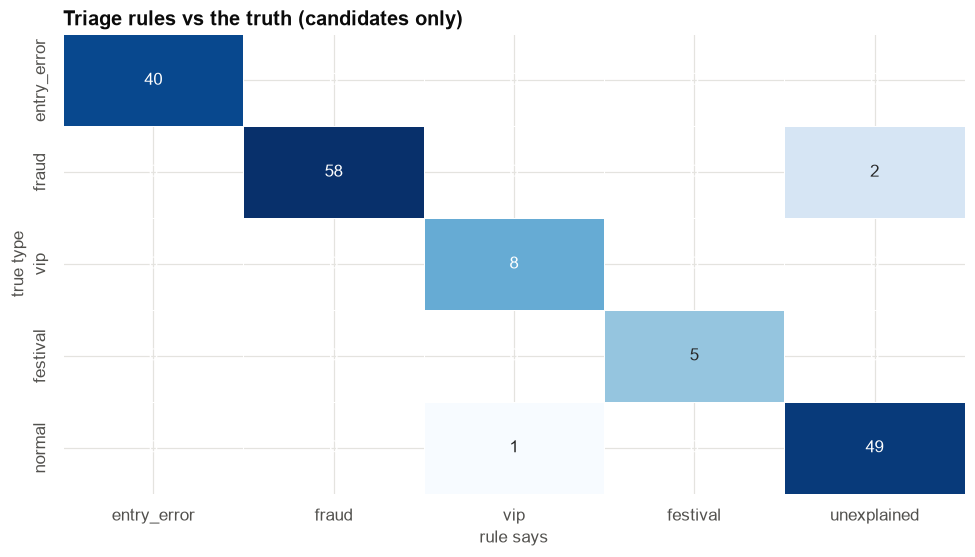

In [14]:
fig, ax = plt.subplots(figsize=(9, 5.2))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False, linewidths=0.5, linecolor="white",
            norm=plt.matplotlib.colors.LogNorm(vmin=1, vmax=max(cm.to_numpy().max(), 2)))
ax.set(title="Triage rules vs the truth (candidates only)")
fig.tight_layout()
save_fig(fig, "fig05_triage_confusion", PATHS["figures"])
plt.show()

**Observation.** Among the 158 candidate payments (the dashboard's queue plus the new screen):
- **Data errors:** 40 called, 40 correct (precision and recall 100%).
- **Fraud:** 58 called, all 58 correct (precision 100%); recall 97%, since two frauds fell into "unexplained".
- **VIP and festival:** the rules call 9 VIP (8 correct, 1 ordinary payment) and 5 festival (all correct). Their
  "recall" (16% and 6%) looks low, but it is low **by design**: of 50 VIP and 80 festival payments, only the 8 and 5
  that the dashboard flagged were ever candidates. The other 117 never triggered an alert, which is the goal.
- **Unexplained:** 51 payments, of which 49 are **ordinary payments that happen to be extreme** and 2 are fraud.

**Interpretation.** Rules built from domain knowledge turn a statistical flag into an **action**: correct, investigate,
whitelist, or ignore. The rules are only as good as the context data. Review them regularly (new fraud tactics,
new festival dates) and **test them on an audited sample**, as we do here with the answer key.

## Section 14 — Does treatment matter? Finance's average ticket size

Finance uses the average payment (ticket size) in its forecasts. The **legitimate-payment average** (excluding errors
and fraud) is what they want; only the answer key knows it. Compare treatments:

In [15]:
clean_amt = pay.loc[~pay["true_type"].isin(["entry_error", "fraud"]), "amount"].to_numpy()   # truth: legitimate payments only
truth = {"mean": clean_amt.mean(), "median": np.median(clean_amt), "trimmed": stats.trim_mean(clean_amt, 0.10)}
amt = pay["amount"].to_numpy()
is_err = (pay["triage"] == "entry_error").to_numpy()
is_fraud_rule = (pay["triage"] == "fraud").to_numpy()
fixed = np.where(is_err, amt / 100, amt)
w99 = np.clip(amt, None, np.quantile(amt, 0.99))
treat = {
    "Do nothing (mean of all payments)": (amt, np.mean),
    "Delete the dashboard's flags (z > 3), then mean": (amt[~pay["f_z"].to_numpy()], np.mean),
    "Delete rule-identified errors and fraud, then mean": (amt[~(is_err | is_fraud_rule)], np.mean),
    "Correct errors (÷100), delete rule-identified fraud, then mean": (fixed[~is_fraud_rule], np.mean),
    "Winsorise at the 99th percentile, then mean": (w99, np.mean),
    "10% trimmed mean (all payments)": (amt, lambda v: stats.trim_mean(v, 0.10)),
    "Median (all payments)": (amt, np.median),
}
rows = []
for name, (v, fn) in treat.items():
    est = fn(v)
    boots = [fn(rng.choice(v, len(v))) for _ in range(300)]
    ref = truth["median"] if name.startswith("Median") else truth["trimmed"] if "trimmed" in name else truth["mean"]
    rows.append({"treatment": name, "estimate (₹)": est, "ci_low": np.percentile(boots, 2.5), "ci_high": np.percentile(boots, 97.5),
                 "same statistic on legitimate payments only (₹)": ref, "bias vs truth (%)": 100 * (est / ref - 1)})
treat_tbl = pd.DataFrame(rows).set_index("treatment")
save_table(treat_tbl, "treatment_comparison", PATHS["tables"])
display(treat_tbl)

,estimate (₹),ci_low,ci_high,same statistic on legitimate payments only (₹),bias vs truth (%)
treatment,,,,,
Do nothing (mean of all payments),"16,009.5611","14,834.1011","17,333.9191","13,629.8410",17.4596
"Delete the dashboard's flags (z > 3), then mean","13,153.4412","12,781.3820","13,560.5756","13,629.8410",-3.4953
"Delete rule-identified errors and fraud, then mean","13,629.2060","13,184.1502","14,032.0047","13,629.8410",-0.0047
"Correct errors (÷100), delete rule-identified fraud, then mean","13,625.0299","13,217.5856","14,039.6499","13,629.8410",-0.0353
"Winsorise at the 99th percentile, then mean","13,246.7383","12,891.6517","13,629.3649","13,629.8410",-2.8108
10% trimmed mean (all payments),"6,707.1513","6,485.3760","6,910.5854","6,601.9503",1.5935
Median (all payments),"2,148.0000","2,075.7375","2,212.7875","2,120.5000",1.2969


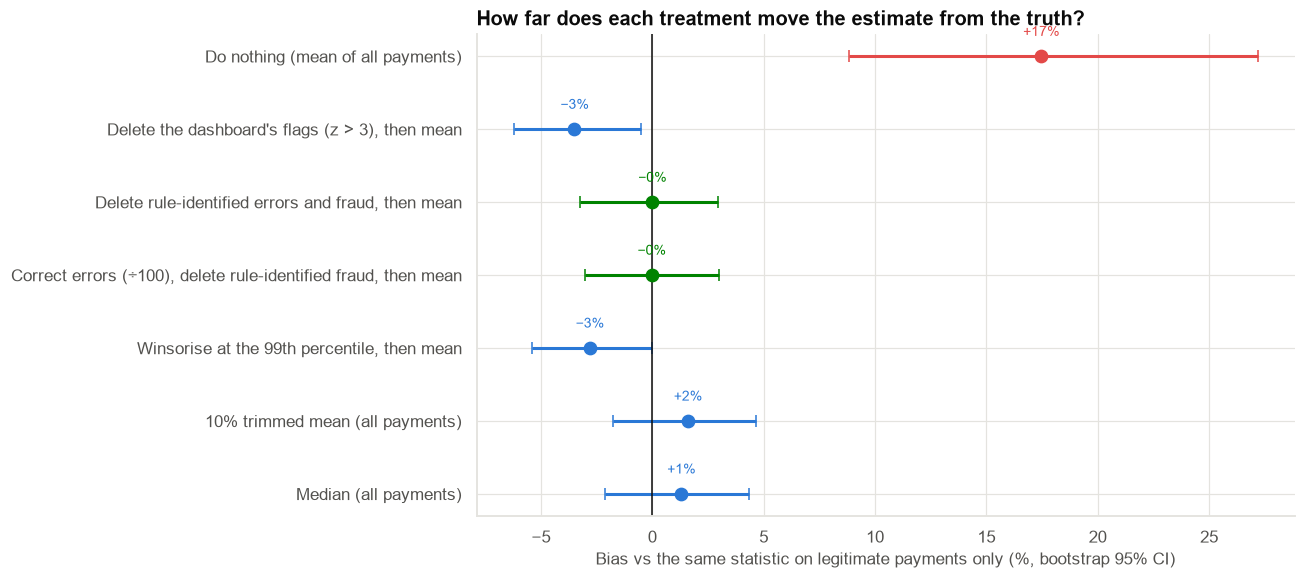

In [16]:
fig, ax = plt.subplots(figsize=(12, 5.4))
tt = treat_tbl.iloc[::-1]
cols = [COLORS["green"] if ("Correct" in k or "Delete rule" in k) else (COLORS["red"] if k.startswith("Do nothing") else PRIMARY) for k in tt.index]
for i, (k, r) in enumerate(tt.iterrows()):
    tr_ = r["same statistic on legitimate payments only (₹)"]
    ax.errorbar(r["bias vs truth (%)"], i, xerr=[[r["bias vs truth (%)"] - 100 * (r["ci_low"] / tr_ - 1)],
                                                  [100 * (r["ci_high"] / tr_ - 1) - r["bias vs truth (%)"]]],
                fmt="o", color=cols[i], capsize=4, ms=8, lw=2)
    ax.text(r["bias vs truth (%)"], i + 0.28, f"{r['bias vs truth (%)']:+.0f}%".replace("-", "−"), ha="center", fontsize=9, color=cols[i])
ax.axvline(0, color=INK, lw=1)
ax.set_yticks(range(len(tt)), tt.index)
ax.set(xlabel="Bias vs the same statistic on legitimate payments only (%, bootstrap 95% CI)", title="How far does each treatment move the estimate from the truth?")
fig.tight_layout()
save_fig(fig, "fig06_treatment_bias", PATHS["figures"])
plt.show()

**Observation.**
- **Doing nothing** overstates the average ticket by **17%** (₹16,010 vs ₹13,630): 40 decimal slips of ×100 add as
  much money as thousands of normal payments.
- **Deleting the dashboard's flags** overshoots in the other direction (**−3.5%**): it removes real VIP and festival
  payments and misses 19 errors; its CI just misses the truth.
- **Deleting rule-identified errors and fraud**, or **correcting the errors (÷100)** and deleting fraud, gets the mean
  within 0.05% of the truth.
- **Winsorising at the 99th percentile** gives **−2.8%**: it caps real VIP and jewellery payments along with the
  errors.
- The **median** (+1.3%) and the **10% trimmed mean** (+1.6%), each compared with the same statistic on legitimate
  payments only, stay close to their own targets without any detective work, but they answer a different question
  (typical payment, not total money).

**Interpretation.**
> **Delete only what is wrong, and only when you know it is wrong.** An outlier that is a **data error** should be
> corrected or removed. A **fraud** payment is a real event that needs action (and is excluded from a "legitimate
> average" by definition, but not from the fraud count). A **VIP or festival payment is data**, and deleting it makes
> the model blind to your best customers.

**Choosing between mean and median.** If the question is about **totals** (revenue, number of payments × average),
the mean is the right statistic and must be cleaned of errors. If the question is about the **typical payment**,
the median is robust and needs no cleaning.

## Section 15 — Outliers and correlation

In [17]:
legit = ~pay["true_type"].isin(["entry_error", "fraud"])
rows = []
for name, mask in [("all payments", np.ones(len(pay), bool)), ("without rule-identified errors", ~(pay["triage"] == "entry_error").to_numpy()),
                   ("without rule-identified errors and fraud", ~pay["triage"].isin(["entry_error", "fraud"]).to_numpy()),
                   ("legitimate payments only (truth)", legit.to_numpy())]:
    sub = pay[mask]
    rows.append({"sample": name, "n": len(sub),
                 "Pearson r (amount, customer's usual)": stats.pearsonr(sub["amount"], sub["customer_avg_amount_90d"])[0],
                 "Spearman ρ": stats.spearmanr(sub["amount"], sub["customer_avg_amount_90d"])[0],
                 "Pearson r (log amount, log usual)": stats.pearsonr(np.log(sub["amount"]), np.log(sub["customer_avg_amount_90d"]))[0]})
cors = pd.DataFrame(rows).set_index("sample")
save_table(cors, "correlation_with_without_outliers", PATHS["tables"])
cors

,n,"Pearson r (amount, customer's usual)",Spearman ρ,"Pearson r (log amount, log usual)"
sample,,,,
all payments,20230,0.3043,0.9328,0.9413
without rule-identified errors,20190,0.8125,0.9357,0.9474
without rule-identified errors and fraud,20132,0.8210,0.9366,0.9485
legitimate payments only (truth),20130,0.8211,0.9367,0.9486


**Observation.** On the raw scale, the Pearson correlation between a payment and the customer's usual payment is
distorted by the decimal-slip errors; removing them raises it a lot. Spearman's rank correlation and the log-log
Pearson correlation barely move.

**Interpretation.** The same lesson as Case 05: a handful of extreme points can create or destroy a Pearson
correlation. Rank-based or log-scale measures are robust to them; and cleaning identified errors restores the
estimate.

## Section 16 — Robust estimation without detecting anything

In [18]:
leg_all = np.log(pay["amount"].to_numpy())
leg_ok = np.log(pay.loc[legit, "amount"].to_numpy())
estimators = {"mean of log amounts (geometric mean)": np.mean, "median": np.median,
              "10% trimmed mean (log scale)": lambda v: stats.trim_mean(v, 0.10),
              "Huber M-estimator (log scale)": lambda v: float(sm.robust.scale.huber(v)[0])}
rows = []
for name, fn in estimators.items():
    a_, c_ = fn(leg_all), fn(leg_ok)
    rows.append({"estimator": name, "typical payment, all payments (₹)": np.exp(a_), "same, legitimate payments only (₹)": np.exp(c_),
                 "contamination effect (%)": 100 * (np.exp(a_ - c_) - 1)})
raw_a, raw_c = pay["amount"].mean(), pay.loc[legit, "amount"].mean()
rows.append({"estimator": "ordinary mean of raw ₹ (for comparison)", "typical payment, all payments (₹)": raw_a,
             "same, legitimate payments only (₹)": raw_c, "contamination effect (%)": 100 * (raw_a / raw_c - 1)})
est = pd.DataFrame(rows).set_index("estimator")
save_table(est, "robust_location_estimates", PATHS["tables"])
est

,"typical payment, all payments (₹)","same, legitimate payments only (₹)",contamination effect (%)
estimator,,,
mean of log amounts (geometric mean),"3,067.1726","3,022.2653",1.4859
median,"2,148.0000","2,120.4995",1.2969
10% trimmed mean (log scale),"2,829.4248","2,797.1578",1.1536
Huber M-estimator (log scale),"2,953.6610","2,919.6190",1.1660
ordinary mean of raw ₹ (for comparison),"16,009.5611","13,629.8410",17.4596


**Observation.** Contamination here is small: 100 bad or fraudulent payments out of 20,230 (0.5%). On the log scale,
every location estimate is within about 1.2–1.5% of its clean-sample value (geometric mean +1.5%, median +1.3%,
trimmed mean +1.2%, Huber +1.2%), while the **ordinary mean of raw ₹ is 17.5% off**. The robust estimators are only
slightly better than the log-scale mean at this contamination level; with 5–10% contamination the gap would widen,
because a mean can be dragged arbitrarily far while a median or M-estimator cannot.

**Rule.** For multiplicative data (money, times, counts of events): **log first**, then use medians or M-estimators if
contamination is plausible. For totals, clean identified errors and keep genuine high values.

## Section 17 — Decision framework: what to do with an outlier

| Question | If YES | If NO |
|---|---|---|
| Is the value **impossible** (breaks a business rule: negative, above a hard limit, wrong units)? | **Data error**: correct if the true value is certain, else remove; fix the source | Continue |
| Does it look like a **decimal / unit slip** (≈ 10×, 100×, 1000×) and is it plausible after rescaling? | Correct it, record the change | Continue |
| Does the **context** point to someone else (new device, location mismatch, burst, night)? | **Fraud / misuse**: investigate; keep it in the data | Continue |
| Is it **normal for this customer or segment** (long history, top tier, in line with their own level)? | **VIP / legitimate**: keep; do not alert | Continue |
| Is it **explained by a known event** (festival, sale, salary day) and fully plausible? | **Rare but real**: keep; add an event feature or calendar | Continue |
| None of the above | **Unexplained**: investigate a sample; keep unless proven wrong | |

| Statistic you need | Outliers present | Use |
|---|---|---|
| Total / average money (forecasts, revenue) | errors present | **Clean errors, keep genuine extremes**; report with and without |
| Typical value | any | **Median** or trimmed mean; log-scale geometric mean |
| Correlation | extreme points | Spearman, or Pearson on the log scale; check the scatterplot |
| Regression | influential points | Cook's distance, robust or log models (Case 10) |
| Alerting / monitoring | skewed money data | **Robust z on the log scale, within segment and relative to the customer, plus context flags** |

**Detector selection rules of thumb**

| Data | Don't | Do |
|---|---|---|
| Right-skewed money / time | z-score on raw values; IQR on raw values | log first, then IQR or robust z |
| Several groups with different levels | one global threshold | thresholds within group |
| Heavy contamination (> 5%) | mean/SD based rules (masking) | MAD / median based rules |
| Time series | global thresholds | thresholds on residuals after trend/season (Case 25) |

## Section 18 — Results

In [19]:
d = det["payments flagged"]; g = grade
summary = pd.DataFrame({"Value": [
    f"{len(pay):,} payments; skewness {stats.skew(pay['amount']):.0f}; mean ÷ median = {pay['amount'].mean() / pay['amount'].median():.1f}",
    f"z > 3: {int(d.iloc[0])}; IQR raw: {int(d.iloc[1]):,}; IQR log: {int(d.iloc[2])}; MAD log: {int(d.iloc[3])}",
    f"SD falls from ₹{masking['SD (₹)'].iloc[0]:,.0f} to ₹{masking['SD (₹)'].iloc[-1]:,.0f} as flagged points are removed ({int(masking['newly flagged'].sum())} flagged over 5 rounds)",
    f"dashboard: {int(g.loc['Dashboard: z > 3 (raw ₹)', 'total flagged'])} flags, {g.loc['Dashboard: z > 3 (raw ₹)', 'errors caught (of 40)']:.0%} of errors, {g.loc['Dashboard: z > 3 (raw ₹)', 'fraud caught (of 60)']:.0%} of fraud",
    f"new screen: {int(g.loc['New screen (segment OR customer OR context)', 'total flagged'])} flags, {g.loc['New screen (segment OR customer OR context)', 'errors caught (of 40)']:.0%} of errors, {g.loc['New screen (segment OR customer OR context)', 'fraud caught (of 60)']:.0%} of fraud",
    f"error rule precision {metrics.loc['entry_error', 'precision']:.0%}, recall {metrics.loc['entry_error', 'recall among all true cases']:.0%}; fraud rule precision {metrics.loc['fraud', 'precision']:.0%}, recall {metrics.loc['fraud', 'recall among all true cases']:.0%}",
    f"do nothing {treat_tbl.iloc[0]['bias vs truth (%)']:+.1f}%; delete dashboard flags {treat_tbl.iloc[1]['bias vs truth (%)']:+.1f}%; correct errors, drop fraud {treat_tbl.iloc[3]['bias vs truth (%)']:+.1f}%".replace("-", "−"),
]}, index=["Data", "Detectors", "Masking", "Dashboard", "New screen", "Triage rules", "Average ticket bias"])
save_table(summary, "results_summary", PATHS["tables"])
summary

,Value
Data,"20,230 payments; skewness 40; mean ÷ median = 7.5"
Detectors,"z > 3: 58; IQR raw: 2,537; IQR log: 16; MAD lo..."
Masking,"SD falls from ₹89,543 to ₹9,954 as flagged poi..."
Dashboard,"dashboard: 58 flags, 52% of errors, 3% of fraud"
New screen,"new screen: 130 flags, 100% of errors, 100% of..."
Triage rules,"error rule precision 100%, recall 100%; fraud ..."
Average ticket bias,do nothing +17.5%; delete dashboard flags −3.5...


## Section 19 — Interpretation

- **The dashboard's rule is the wrong tool:** a z-score on raw skewed amounts both **swamps** the queue with harmless
  large payments and **masks** real problems, and it knows nothing about segments or customers.
- **Outliers are four different things**; the right action depends on which. Context variables, not the amount
  alone, tell them apart.
- **Treatment drives the numbers Finance uses.** Leaving 40 keying errors in the data overstates the average ticket
  hugely; blindly deleting the biggest payments removes real revenue.

## Section 20 — What can we say?

| ✅ We can say | ❌ We cannot say |
|---|---|
| "Segment-aware, customer-relative and context lenses flagged X payments; Y% of the flagged errors were confirmed." | "These are the outliers" as if there were one definition. |
| "The 40 manually keyed payments of ~100× the customer's usual amount are very likely decimal-slip errors." | "They are errors" without checking the source records. |
| "Deleting errors changes the average ticket by about X%; deleting all large payments changes it by Y%." | "Outliers should be removed." |
| "VIP and festival payments are normal for the customers who make them." | "Big payments are suspicious." |

## Section 21 — Business interpretation

- **Alerting:** replace the "3 SD" rule with the combined screen; send **data errors** to a correction workflow,
  **fraud candidates** to investigators, and keep VIP and festival payments **off** the queue.
- **Keying controls:** most errors come from manual entry: add range checks against the customer's history and a
  "×100?" prompt.
- **Finance:** use the cleaned average (or the median, with a bootstrap CI) in forecasts, and report both.

## Section 22 — Limitations

- The rules are tuned to this simulated mix of outlier types; in real data, the types overlap more.
- Fraud labels here come from simulation. In production, the confirmed-fraud rate lags by weeks (Case 12).
- Thresholds (3.5, ratio ≥ 20, 3 flags) are choices; the sensitivity to them should be studied on audited samples.
- Synthetic data.

## Section 23 — Final recommendation

> **Retire the "3 SD" dashboard rule.** Screen payments with **three lenses** (unusual for the segment, unusual for the
> customer, several risk flags) on the **log scale**, triage the flags with the **four-type rules**, and treat each type
> differently: **correct** data errors, **investigate** fraud, **keep and whitelist** VIP and festival payments.
> **Report average ticket size after correcting identified errors, alongside the median.** Audit a random sample of
> flagged **and unflagged** payments every quarter to keep the rules honest.

## Section 24 — What would I do next?

1. **Audit a stratified sample** (flagged and unflagged) to estimate precision and recall of each rule without an
   answer key.
2. Build a **supervised fraud model** (Case 12) once enough confirmed labels exist; use these lenses as features.
3. Add **keying controls** at the source and track the error rate over time.
4. Add a **festival calendar** feature so seasonal peaks stop looking like outliers.
5. Continue to **Case 17** (missing data: when is it safe to drop or fill?).